# 03 - Model Training, Tuning and Selection

**Goal:** train four classifiers, tune them fairly, compare them with an *unbiased* estimate of performance, and pick one **without looking at the test set**.

| # | Model | Role |
|---|---|---|
| 1 | Logistic Regression | Simple, interpretable baseline |
| 2 | Random Forest | Bagged trees, handles non-linearity and interactions |
| 3 | Gradient Boosting (scikit-learn) | Sequential boosted trees |
| 4 | XGBoost | Regularised boosted trees |

A trivial *majority-class* classifier is added as a reference floor.

### Protocol

```
                 303 patients
                      |
        stratified 80 / 20 split (seed 42)
            |                          |
   242 training patients          61 test patients  ---> untouched until notebook 04
            |
   Nested cross-validation (5 folds x 3 repeats = 15 outer folds)
     outer fold:  train part --> GridSearchCV (5-fold, scored by ROC-AUC) --> best params
                  validation part --> score the tuned model  (accuracy, precision, recall, F1, ROC-AUC)
            |
   mean +/- SD over the 15 outer folds  --->  choose the model with the best ROC-AUC
            |
   re-tune the chosen configuration on all 242 training patients  --->  save to models/
```

*Why nested CV?* If the same folds are used to tune hyper-parameters **and** to report performance, the reported score is optimistically biased - a real risk with only 242 training patients. In nested CV the tuning happens inside each outer training part, so the outer validation score is honest.

In [1]:
import sys, warnings, time, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import preprocessing as pp
from src import train as tr
from src import evaluate as ev

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

X_train, X_test, y_train, y_test = pp.get_split()
print(f"Training set: {X_train.shape}   (test set of {len(X_test)} patients is not used in this notebook)")

N_REPEATS = 3
models = tr.get_models()

Training set: (242, 13)   (test set of 61 patients is not used in this notebook)


## 1. Models and hyper-parameter grids

Every model is a scikit-learn `Pipeline`: the preprocessing from notebook 02 followed by the classifier. Grids are deliberately small - with 242 training patients a large search would mostly tune to noise.

In [2]:
pd.DataFrame([
    {"model": n,
     "grid": {k.replace("clf__", ""): v for k, v in g.items()},
     "combinations": int(np.prod([len(v) for v in g.values()]))}
    for n, (e, g) in models.items()
]).set_index("model")

,grid,combinations
model,,
Logistic Regression,"{'C': [0.01, 0.1, 1, 10, 100]}",5
Random Forest,"{'max_depth': [3, 5, None], 'min_samples_leaf'...",9
Gradient Boosting,"{'n_estimators': [50, 100, 200], 'learning_rat...",12
XGBoost,"{'n_estimators': [100, 200], 'learning_rate': ...",12


## 2. Reference floor: majority-class classifier

Any useful model must beat this.

In [3]:
summary = {}
base = tr.baseline_cv(X_train, y_train, n_repeats=N_REPEATS)
summary["Majority-class baseline"] = tr.summarise(base)
base.mean().round(3).to_frame("mean over outer folds").T

,accuracy,precision,recall,f1,roc_auc
mean over outer folds,0.541,0.0,0.0,0.0,0.5


Always predicting "no disease" gives ~54 % accuracy (the majority share), zero recall and ROC-AUC = 0.5. That is the number to beat - and it shows why accuracy alone is a weak yardstick.

## 3. Nested cross-validation

In [4]:
fold_frames, fold_params = [], {}

for name, (est, grid) in models.items():
    t0 = time.time()
    folds, params = tr.nested_cv(est, grid, X_train, y_train, n_repeats=N_REPEATS)
    summary[name] = tr.summarise(folds)
    fold_frames.append(folds.assign(model=name))
    fold_params[name] = params
    print(f"{name:<22} ROC-AUC = {summary[name]['roc_auc_mean']:.3f} +/- {summary[name]['roc_auc_std']:.3f}"
          f"   ({time.time() - t0:.0f} s)")

cv_summary = pd.DataFrame(summary).T
folds_long = pd.concat(fold_frames, ignore_index=True)

Logistic Regression    ROC-AUC = 0.888 +/- 0.050   (7 s)


Random Forest          ROC-AUC = 0.892 +/- 0.039   (123 s)


Gradient Boosting      ROC-AUC = 0.867 +/- 0.049   (74 s)


XGBoost                ROC-AUC = 0.876 +/- 0.043   (33 s)


In [5]:
labels = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1", "roc_auc": "ROC-AUC"}
table = pd.DataFrame({
    labels[m]: [f"{cv_summary.loc[n, m + '_mean']:.3f} +/- {cv_summary.loc[n, m + '_std']:.3f}" for n in cv_summary.index]
    for m in tr.METRICS
}, index=cv_summary.index)
table

,Accuracy,Precision,Recall,F1,ROC-AUC
Majority-class baseline,0.541 +/- 0.007,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.500 +/- 0.000
Logistic Regression,0.829 +/- 0.048,0.857 +/- 0.089,0.768 +/- 0.093,0.804 +/- 0.058,0.888 +/- 0.050
Random Forest,0.809 +/- 0.054,0.812 +/- 0.065,0.762 +/- 0.095,0.783 +/- 0.065,0.892 +/- 0.039
Gradient Boosting,0.804 +/- 0.055,0.802 +/- 0.080,0.771 +/- 0.094,0.782 +/- 0.064,0.867 +/- 0.049
XGBoost,0.796 +/- 0.056,0.787 +/- 0.067,0.768 +/- 0.103,0.773 +/- 0.067,0.876 +/- 0.043


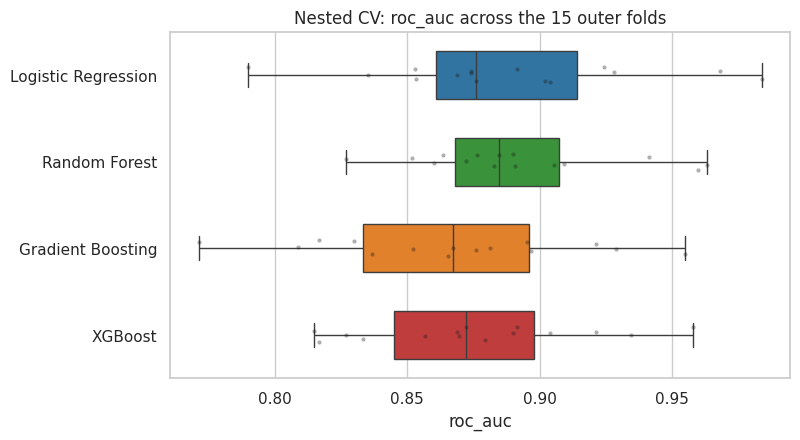

In [6]:
fig = ev.plot_cv_distribution(folds_long, "roc_auc")
plt.show()

**Observations - model comparison (nested CV, 242 training patients)**

* **All four models clearly beat the baseline**: ROC-AUC 0.87-0.89 vs 0.50, accuracy 0.80-0.83 vs 0.54.
* **The models are statistically very close.** Random Forest has the highest mean ROC-AUC (0.892), followed by Logistic Regression (0.888), XGBoost (0.876) and Gradient Boosting (0.867), but the fold-to-fold standard deviation is 0.04-0.05 - larger than every gap between models. The box plot shows almost complete overlap.
* **A simple linear baseline is as good as the ensembles.** Logistic Regression actually has the best accuracy (0.829), precision (0.857) and F1 (0.804), while all models reach a similar recall of about 0.76-0.77. This is a common finding on small tabular medical data and is a result worth reporting: added model complexity did not buy accuracy here.
* **Recall is the weak spot.** At the default 0.5 threshold every model misses roughly one in four patients with disease (recall ~0.77). In a screening context that matters more than accuracy; notebook 04 studies the threshold trade-off.

### Paired comparison against the selected model

All models were evaluated on **identical outer folds**, so we can compare them fold by fold. (The 15 folds overlap in their training data, so this is descriptive, not a formal significance test.)

In [7]:
real = cv_summary.drop(index="Majority-class baseline")
best = real["roc_auc_mean"].idxmax()
print(f"Selected model (highest nested-CV ROC-AUC): {best}\n")

sel = folds_long.loc[folds_long.model == best, "roc_auc"].to_numpy()
rows = []
for n in real.index.drop(best):
    other = folds_long.loc[folds_long.model == n, "roc_auc"].to_numpy()
    d = sel - other
    rows.append({"compared with": n, "mean ROC-AUC difference": d.mean(),
                 "SD of difference": d.std(ddof=1), f"folds won by {best}": f"{(d > 0).sum()} / {len(d)}"})
pd.DataFrame(rows).set_index("compared with").round(3)

Selected model (highest nested-CV ROC-AUC): Random Forest



,mean ROC-AUC difference,SD of difference,folds won by Random Forest
compared with,,,
Logistic Regression,0.003,0.032,8 / 15
Gradient Boosting,0.025,0.024,14 / 15
XGBoost,0.016,0.013,14 / 15


The selected model's advantage is **negligible against Logistic Regression** (mean difference 0.003, ahead in only 8 of 15 folds - a coin flip) and **small but fairly consistent against the two boosting models** (0.016-0.025 ROC-AUC, ahead in 14 of 15 folds). **The selection is therefore a tie-break by the pre-defined rule (highest nested-CV ROC-AUC), not evidence that Random Forest is truly superior to a simple logistic regression.** We keep the rule fixed so that the choice cannot be influenced by test-set results.

### Hyper-parameter stability

How consistently did the inner search choose the same configuration across the 15 outer folds?

In [8]:
for name, plist in fold_params.items():
    counts = Counter(json.dumps({k.replace("clf__", ""): v for k, v in p.items()}, sort_keys=True) for p in plist)
    print(f"{name}")
    for cfg, c in counts.most_common(3):
        print(f"   {c:>2}/{len(plist)}  {cfg}")

Logistic Regression
   10/15  {"C": 0.1}
    3/15  {"C": 1}
    1/15  {"C": 100}
Random Forest
    4/15  {"max_depth": 3, "min_samples_leaf": 5}
    4/15  {"max_depth": null, "min_samples_leaf": 3}
    2/15  {"max_depth": 3, "min_samples_leaf": 1}
Gradient Boosting
    8/15  {"learning_rate": 0.05, "max_depth": 2, "n_estimators": 50}
    4/15  {"learning_rate": 0.1, "max_depth": 2, "n_estimators": 50}
    2/15  {"learning_rate": 0.1, "max_depth": 3, "n_estimators": 100}
XGBoost
    5/15  {"learning_rate": 0.03, "max_depth": 2, "n_estimators": 100}
    4/15  {"learning_rate": 0.03, "max_depth": 2, "n_estimators": 200}
    1/15  {"learning_rate": 0.1, "max_depth": 2, "n_estimators": 100}


**Reading the table:** the inner search does not always pick the same configuration (e.g. Logistic Regression chose `C = 0.1` in 10 of 15 folds but `C = 1` on the full training set; the Random Forest choices are spread over several settings). Many neighbouring configurations perform almost identically - the performance surface is flat, which is typical for small datasets. The boosting models consistently prefer very small models (depth 2, few rounds, low learning rate).

## 4. Final tuning on the full training set and saving

Each model's grid is searched once more (5-fold CV, ROC-AUC) on all 242 training patients; the best configuration is refitted and saved as a complete `Pipeline` (preprocessing + classifier) to `models/`.

In [9]:
final_models, best_params = {}, {}
for name, (est, grid) in models.items():
    final = tr.fit_final(est, grid, X_train, y_train)
    final_models[name] = final.best_estimator_
    best_params[name] = {k.replace("clf__", ""): v for k, v in final.best_params_.items()}

pd.DataFrame({"selected hyper-parameters": best_params}).rename_axis("model")

,selected hyper-parameters
model,
Logistic Regression,{'C': 1}
Random Forest,"{'max_depth': 3, 'min_samples_leaf': 1}"
Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est..."
XGBoost,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est..."


In [10]:
selected = tr.save_artifacts(final_models, cv_summary, folds_long, best_params)
print("Selected model:", selected)
print("Saved:", *sorted(p.name for p in pp.MODELS_DIR.glob("*.joblib")), sep="\n  ")
print("Tables: results/cv_results.csv, results/cv_fold_scores.csv, results/best_params.json")

Selected model: Random Forest
Saved:
  best_model.joblib
  gradient_boosting.joblib
  logistic_regression.joblib
  random_forest.joblib
  xgboost.joblib
Tables: results/cv_results.csv, results/cv_fold_scores.csv, results/best_params.json


## 5. Summary

* Four tuned pipelines were trained on the 242 training patients and compared with nested cross-validation; the model with the highest ROC-AUC (**Random Forest**, 0.892 +/- 0.039) was selected and saved as `models/best_model.joblib`.
* Differences between the four models are within noise; a regularised logistic regression performs on par with the tree ensembles.
* The selected hyper-parameters (shallow trees, few boosting rounds, low learning rates, `C` around 0.1-1) reflect the small sample: simple, strongly regularised models generalise best here.
* The **test set has not been touched.**

**Next:** `04_model_evaluation.ipynb` - one-time evaluation on the held-out test set: metrics with confidence intervals, ROC / precision-recall / calibration curves, confusion matrices, threshold analysis and feature importance.